Data Cleaning and Handling, Exploratary Data Analysis, Smoothing Parameters for the Model

In [2]:
import pandas as pd 
import numpy as np
import yfinance as yf
import datetime
import requests
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


Data Cleaning and Handling

In [3]:
#pull market data from yahoo finance using tickers

def pull_market_data():
    
    #defining the timeline 
    start_date = "2016-01-01" #fixed date : start of EV/Renewable shift 
    end_date = datetime.datetime.now().strftime("%Y-%m-%d") #dynamic date : current date
    
    print (f"Fetching market data from {start_date} to {end_date}")
    
    #downloading the daily raw data
    tickers = ["BZ=F", "CL=F", "DX-Y.NYB", "^VIX"]
    raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']
    
    #rename columns for clarity
    raw_data.columns = ["Brent_Crude", "WTI_Crude", "US_Dollar_Index", "VIX_Index"]
    
    #clean the dataset, resampling to uniform weekly frequency Friday close
    print("Downsampling to uniform weekly frequency (Friday close)")
    weekly_data = raw_data.resample('W-FRI').last()
    
    #handling the missing data 
    cleaned_data = weekly_data.ffill().dropna()
    
    return cleaned_data

def pull_opec_data():
    #fetch data from the EIA api 
    eia_api_key = __import__("os").environ.get("EIA_API_KEY", "")
    series_id = 'COPR_OPECPLUS' 
    url = f"https://api.eia.gov/v2/steo/data/?api_key={eia_api_key}&frequency=monthly&data[0]=value&facets[seriesId][]={series_id}"
    
    response = requests.get(url)
    if response.status_code == 200: #status code 200 means the request was successful
        data = response.json()
        opec_df = pd.DataFrame(data['response']['data']) 
        opec_df = opec_df[['period', 'value']].copy()
        opec_df.rename(columns={'value': 'OPEC_Plus_Production'}, inplace=True)
        
        opec_df['OPEC_Plus_Production'] = opec_df['OPEC_Plus_Production'].astype(float)
        
        #convert to datetime 
        opec_df['period'] = pd.to_datetime(opec_df['period'] + '-01') #adding '-01' to convert to first day of the month
        opec_df.set_index('period', inplace=True)
        opec_df.sort_index(inplace=True)
        return opec_df
    else:
        print("Error fetching OPEC data. Status Code: {response.status_code}")
        return None
    
def build_master_dataset():
    #this function will pull both market datas from the two functions above, merge them and handle the frequency mismatch between the two datasets
    print("Pulling Financial Market Data...")
    financial_df = pull_market_data()
    
    print("Pulling OPEC+ Supply Data...")
    opec_df = pull_opec_data()
    
    print("Merging into Master Matrix...")
    #merge using outer join and forward-fill the monthly data 
    master_dataset = pd.merge(financial_df, opec_df, left_index=True, right_index=True, how='outer')
    master_dataset['OPEC_Plus_Production'] = master_dataset['OPEC_Plus_Production'].ffill()
    
    #trimming the edges to match the start/end dates that i want
    master_dataset = master_dataset.loc[financial_df.index.min() : financial_df.index.max()]
    
    master_dataset = master_dataset.dropna(subset=['Brent_Crude']) #drop any remaining NaN values
    
    return master_dataset

if __name__ == "__main__":
    master_dataset = build_master_dataset()
    print("\n--- Dynamically Pulled Cleaned Weekly Dataset ---")
    print(master_dataset.tail())
    

Pulling Financial Market Data...
Fetching market data from 2016-01-01 to 2026-07-23


/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_93432/359705254.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  4 of 4 completed


Downsampling to uniform weekly frequency (Friday close)
Pulling OPEC+ Supply Data...
Merging into Master Matrix...

--- Dynamically Pulled Cleaned Weekly Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    94.070000  86.830002       101.139999  16.639999   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  


Exploratary Data Analysis

In [4]:
# 1. Descriptive Statistics (Mean, Std, Min, Max)
print("--- Summary Statistics ---")
summary_stats = master_dataset.describe()
print(summary_stats)

# 2. Correlation Matrix (Understanding linear relationships)
print("\n--- Correlation Matrix ---")
correlation_matrix = master_dataset.corr()
print(correlation_matrix)

--- Summary Statistics ---
       Brent_Crude   WTI_Crude  US_Dollar_Index   VIX_Index  \
count   551.000000  551.000000       551.000000  551.000000   
mean     69.045154   64.703357        98.557804   18.314047   
std      18.296856   17.865366         4.898283    7.027441   
min      21.440001   16.940001        89.070000    9.140000   
25%      56.060001   52.240002        95.134998   13.465000   
50%      68.690002   63.889999        98.010002   16.500000   
75%      79.720001   75.535000       102.169998   21.290000   
max     122.010002  120.669998       113.309998   66.040001   

       OPEC_Plus_Production  
count            551.000000  
mean              34.752785  
std                2.642224  
min               25.340090  
25%               32.937900  
50%               35.094100  
75%               36.894100  
max               38.864900  

--- Correlation Matrix ---
                      Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
Brent_Crude              1.0000

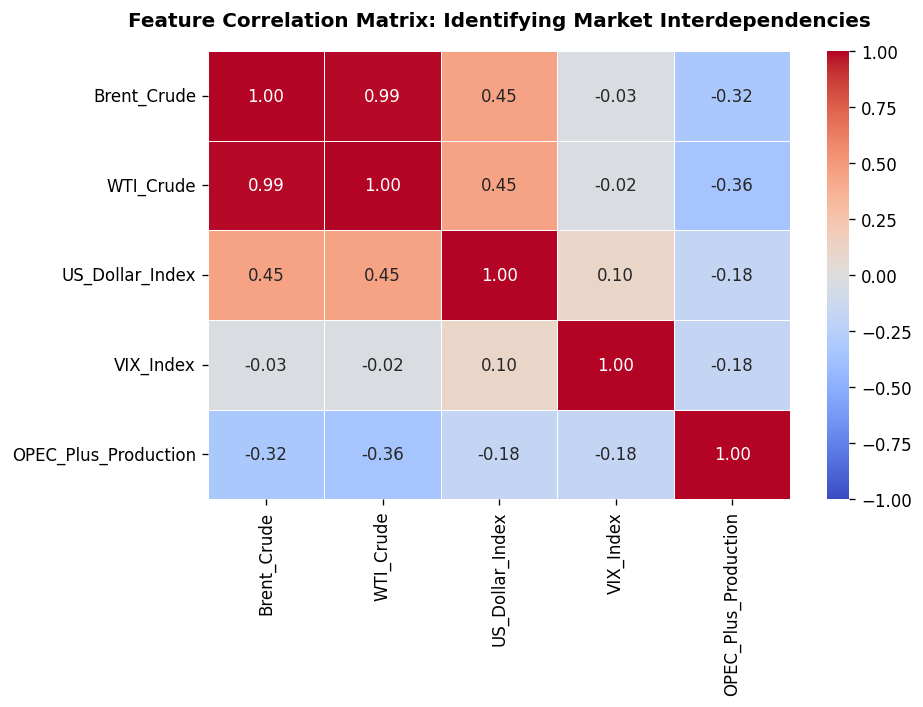

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6), dpi=120)
# Calculate correlation on the raw features
corr_matrix = master_dataset[["Brent_Crude", "WTI_Crude", "US_Dollar_Index", "VIX_Index", "OPEC_Plus_Production"]].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix: Identifying Market Interdependencies', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [6]:
#normalization of the data for better comparison

#log scale transformation for the Brent Crude (using log1p for safety)
master_dataset["Brent_Log"] = np.log1p(master_dataset["Brent_Crude"])

#z-score normalization for the regression components (WTI Crude, US Dollar Index, VIX Index)
scaler = StandardScaler()
z_score_columns = ["WTI_Crude", "US_Dollar_Index", "VIX_Index", "OPEC_Plus_Production"]

#creating 4 brand new columns with a '_Z' suffix so we don't erase the raw data
z_new_names = ["WTI_Z", "USD_Z", "VIX_Z", "OPEC_Z"]
master_dataset[z_new_names] = scaler.fit_transform(master_dataset[z_score_columns])

print("Normalization complete! New columns added to master_dataset.")

print("\n--- Raw vs Normalized Dataset ---")
print(master_dataset[["Brent_Crude", "WTI_Crude", "US_Dollar_Index", "VIX_Index", "OPEC_Plus_Production"]].tail())

Normalization complete! New columns added to master_dataset.

--- Raw vs Normalized Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    94.070000  86.830002       101.139999  16.639999   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  


Smoothing Algorithms for the Models

In [7]:
#smoothing parameter for models like SARIMAX 

#simple moving average (4-weeks)
master_dataset['SMA_4'] = master_dataset['Brent_Crude'].rolling(window=4).mean()

#exponential moving average (4-weeks)
master_dataset['EMA_4'] = master_dataset['Brent_Crude'].ewm(span=4, adjust=False).mean() #EMA gives more weight to recent prices, reacting faster to market shocks

#rolling median (4-weeks)
master_dataset['Median_4'] = master_dataset['Brent_Crude'].rolling(window=4).median() #Finds the middle ground; ignores extreme freak spikes like the 2020 crash

#drop the NaN values that is created by the intial rolling window
master_dataset = master_dataset.dropna()

print("\n--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---")
print(master_dataset.tail())


--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    94.070000  86.830002       101.139999  16.639999   

            OPEC_Plus_Production  Brent_Log     WTI_Z     USD_Z     VIX_Z  \
2026-06-26             26.937156   4.290322  0.253606  0.572597  0.013666   
2026-07-03             27.516865   4.287716  0.223352  0.470428 -0.308222   
2026-07-10             27.516865   4.343935  0.375740  0.492905 -0.467742   
2026-07-17             27.516865   4.489759  0.996498  0.447950  0.064941   
2026-07-24             27.516865   4.554613  1.239647  0.527642 -0.238432   

              OPEC_Z      SMA_4      EMA_4   Median_4  
2026-06-26 -2.96066

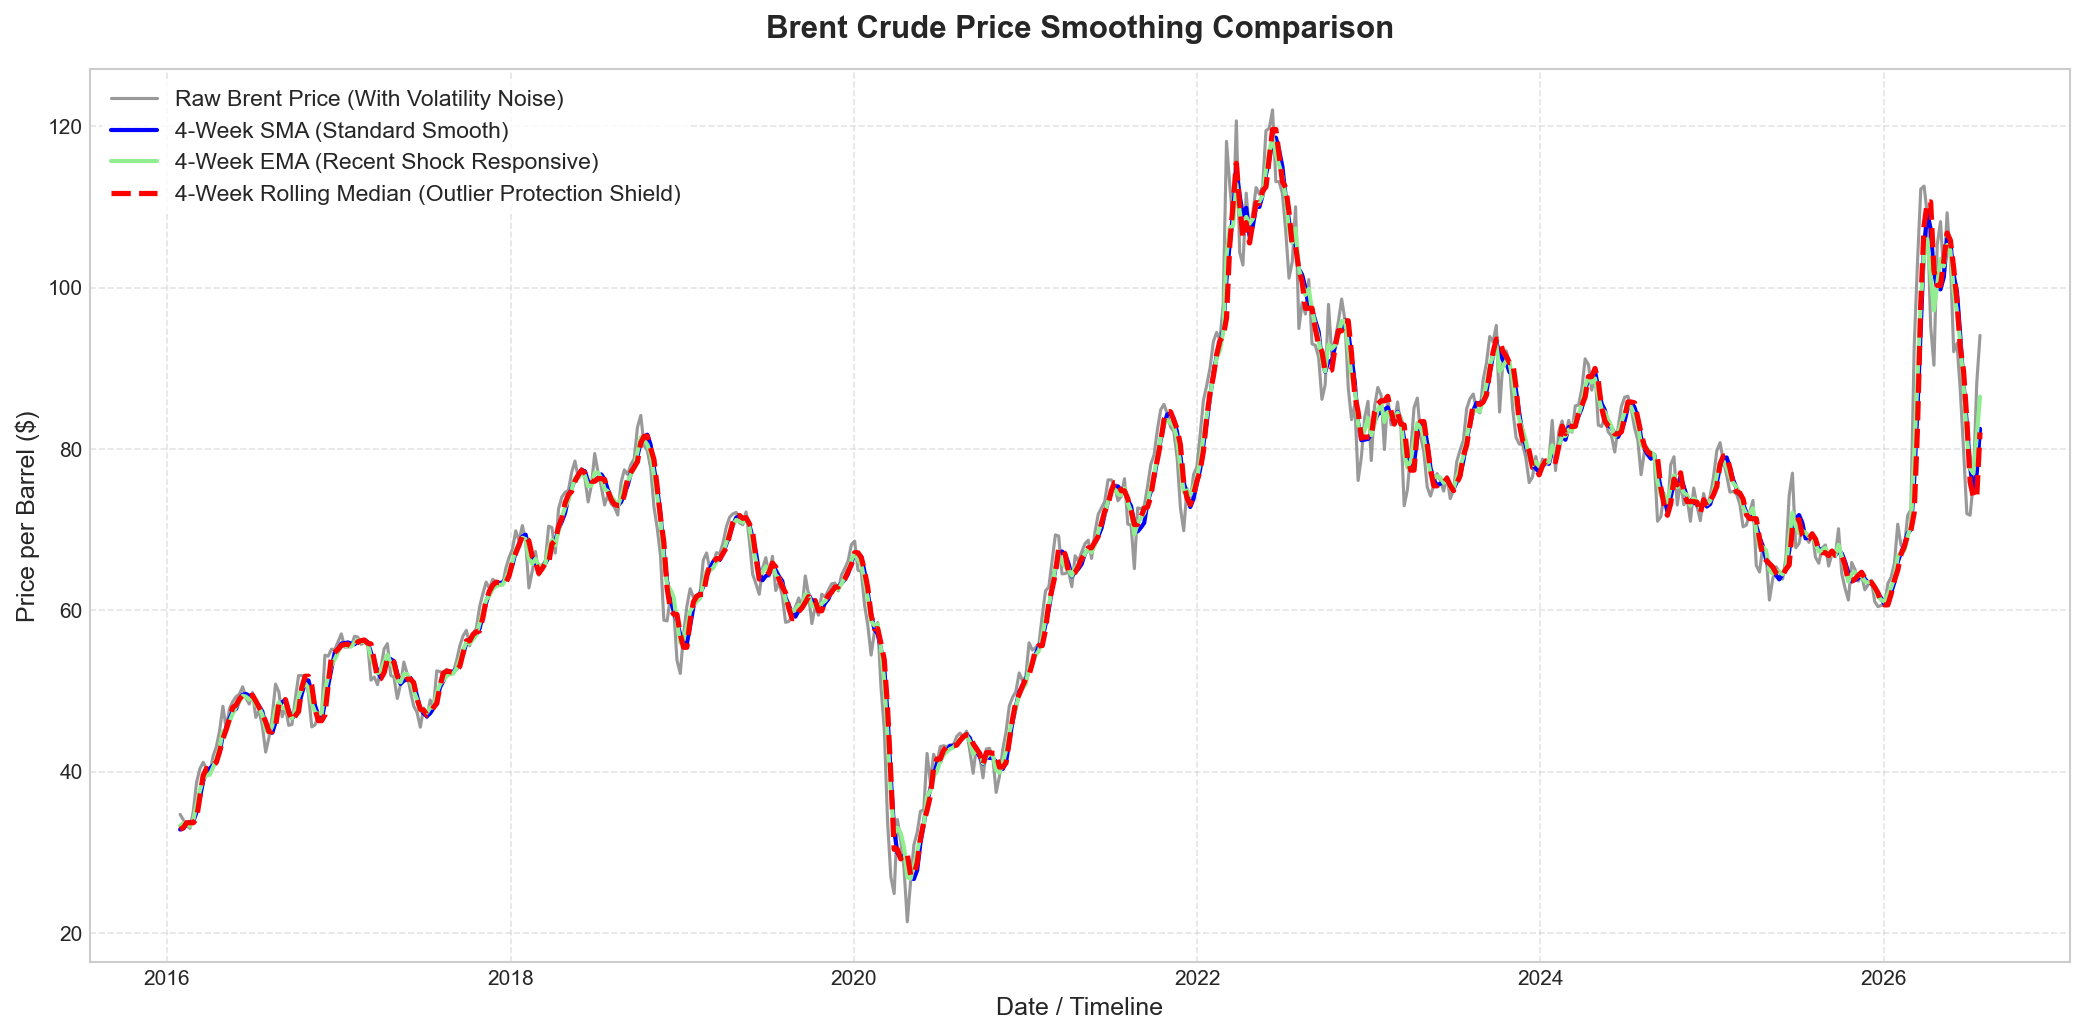

In [8]:
#visualization of the smoothed data

#setting the style and create a crisp, high-resolution figure
plt.style.use('seaborn-v0_8-whitegrid') if 'seaborn-v0_8-whitegrid' in plt.style.available else plt.style.use('default')
plt.figure(figsize=(14, 7), dpi=150)

#1. plot the Raw Noisy Price in the background with a lighter color
plt.plot(master_dataset.index, master_dataset['Brent_Crude'], 
         label='Raw Brent Price (With Volatility Noise)', color='grey', alpha=0.8, linewidth=1.5)

#2. plot the Simple Moving Average (SMA)
plt.plot(master_dataset.index, master_dataset['SMA_4'], 
         label='4-Week SMA (Standard Smooth)', color='blue', linewidth=2)

#3. plot the Exponential Moving Average (EMA)
plt.plot(master_dataset.index, master_dataset['EMA_4'], 
         label='4-Week EMA (Recent Shock Responsive)', color='lightgreen', linewidth=2)

#4. plot the Rolling Median (Outlier Protection Shield)
plt.plot(master_dataset.index, master_dataset['Median_4'], 
         label='4-Week Rolling Median (Outlier Protection Shield)', color='red', linestyle='--', linewidth=2.5)

#customize the chart labels and text to match your presentation narrative
plt.title('Brent Crude Price Smoothing Comparison', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Date / Timeline', fontsize=12)
plt.ylabel('Price per Barrel ($)', fontsize=12)
plt.legend(fontsize=11, loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.grid(True, linestyle='--', alpha=0.5)

#clean look
plt.tight_layout()

plt.show()

Brent Crude P-Value: 0.3249
-> Result: Brent Crude is Non-Stationary (Mountain). We must difference it for SARIMAX.
OPEC Supply P-Value: 0.4773
-> Result: OPEC Supply is Non-Stationary.


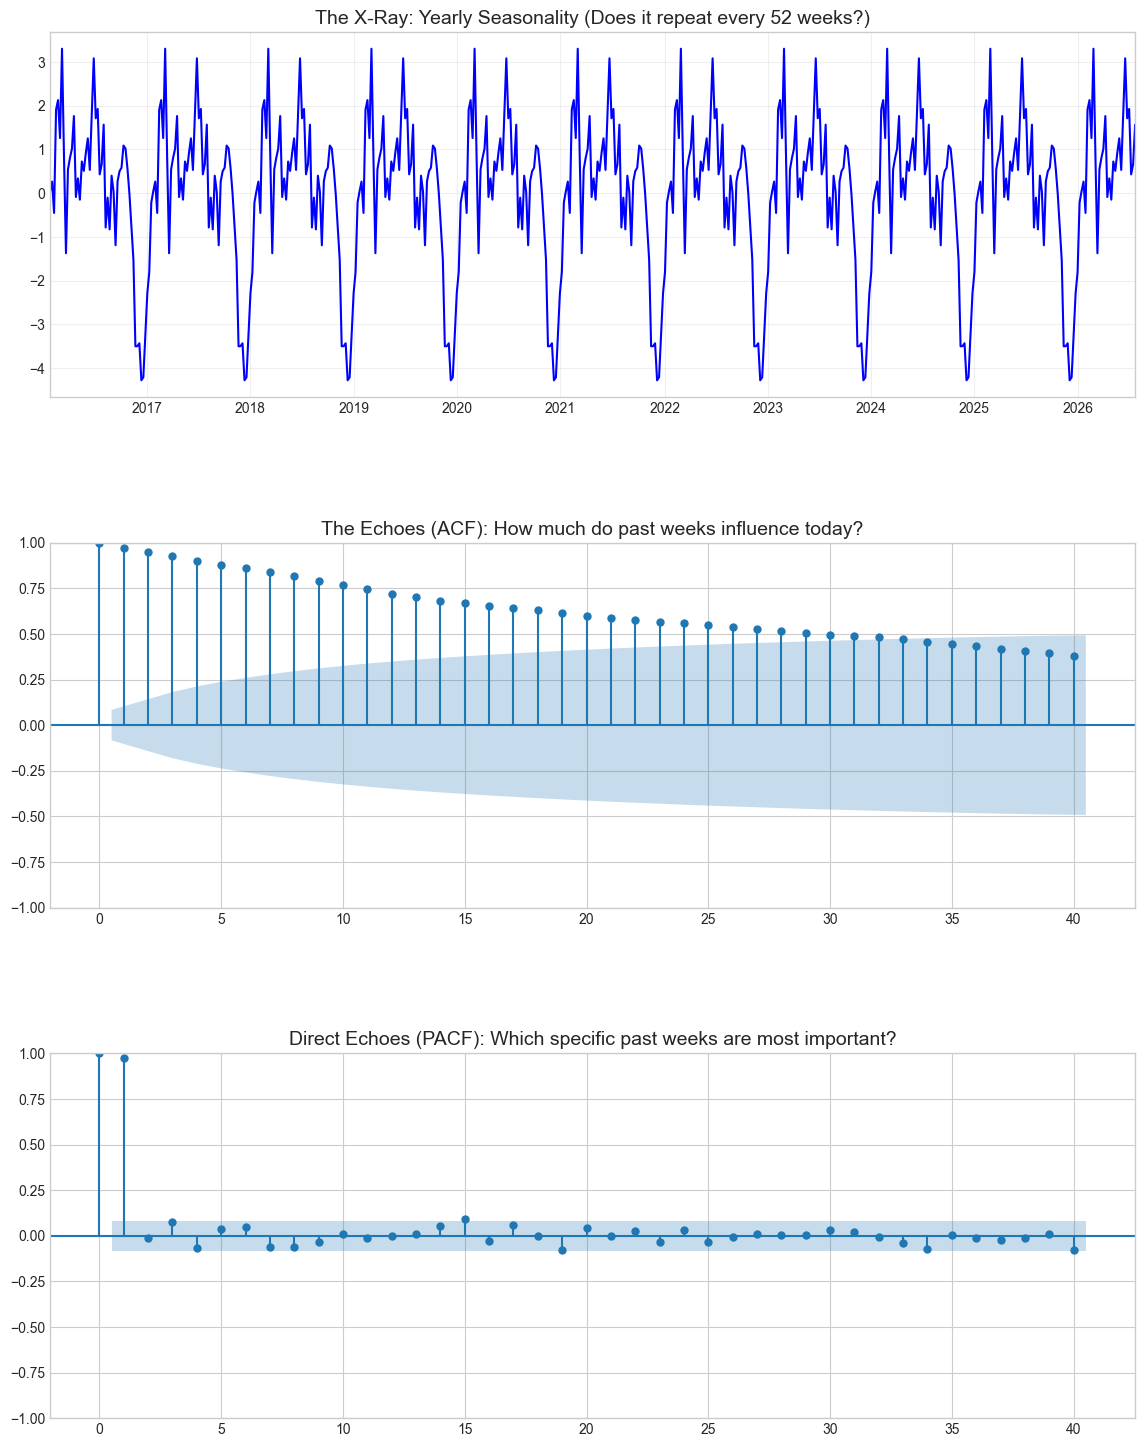

In [9]:
#time series decomposition for trend and seasonality analysis

# Drop NaNs just for testing to prevent errors
test_data = master_dataset.dropna()

# Testing Brent Crude
adf_brent = adfuller(test_data['Brent_Crude'])
print(f"Brent Crude P-Value: {adf_brent[1]:.4f}")
if adf_brent[1] > 0.05:
    print("-> Result: Brent Crude is Non-Stationary (Mountain). We must difference it for SARIMAX.")
else:
    print("-> Result: Brent Crude is Stationary (Treadmill).")

# Testing OPEC Production
adf_opec = adfuller(test_data['OPEC_Plus_Production'])
print(f"OPEC Supply P-Value: {adf_opec[1]:.4f}")
if adf_opec[1] > 0.05:
    print("-> Result: OPEC Supply is Non-Stationary.")
else:
    print("-> Result: OPEC Supply is Stationary.")


# --- VISUAL TESTS (X-RAY & ECHOES) ---
# Create a large visual dashboard
fig, axes = plt.subplots(3, 1, figsize=(14, 18))
plt.subplots_adjust(hspace=0.4)

# Plot A: The X-Ray (Decomposition)
decomposition = seasonal_decompose(test_data['Brent_Crude'], model='additive', period=52)
decomposition.seasonal.plot(ax=axes[0], color='blue')
axes[0].set_title("The X-Ray: Yearly Seasonality (Does it repeat every 52 weeks?)", fontsize=14)
axes[0].grid(True, alpha=0.3)

# Plot B: The Echoes (ACF)
plot_acf(test_data['Brent_Crude'], lags=40, ax=axes[1])
axes[1].set_title("The Echoes (ACF): How much do past weeks influence today?", fontsize=14)

# Plot C: The Direct Echoes (PACF)
plot_pacf(test_data['Brent_Crude'], lags=40, ax=axes[2])
axes[2].set_title("Direct Echoes (PACF): Which specific past weeks are most important?", fontsize=14)

plt.show()



In [10]:
print(master_dataset[["Brent_Crude", "WTI_Crude", "US_Dollar_Index", "VIX_Index", "OPEC_Plus_Production"]].tail().round(3).to_string())

            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  OPEC_Plus_Production
2026-06-26        71.99      69.23           101.36      18.41                26.937
2026-07-03        71.80      68.69           100.86      16.15                27.517
2026-07-10        76.01      71.41           100.97      15.03                27.517
2026-07-17        88.10      82.49           100.75      18.77                27.517
2026-07-24        94.07      86.83           101.14      16.64                27.517


In [11]:
# Summary statistics table for Sprint 1.2 EDA slide

summary_stats = master_dataset[
    ["Brent_Crude", "WTI_Crude", "US_Dollar_Index", "VIX_Index", "OPEC_Plus_Production"]
].describe().loc[["mean", "std", "min", "max"]].T.round(2)

summary_stats

,mean,std,min,max
Brent_Crude,69.25,18.14,21.44,122.01
WTI_Crude,64.88,17.74,16.94,120.67
US_Dollar_Index,98.56,4.91,89.07,113.31
VIX_Index,18.27,7.02,9.14,66.04
OPEC_Plus_Production,34.74,2.64,25.34,38.86


In [12]:
master_dataset[
    ["Brent_Crude", "Brent_Log", "WTI_Z", "USD_Z", "VIX_Z", "OPEC_Z"]
].tail().round(3)

,Brent_Crude,Brent_Log,WTI_Z,USD_Z,VIX_Z,OPEC_Z
2026-06-26,71.99,4.290,0.254,0.573,0.014,-2.961
2026-07-03,71.80,4.288,0.223,0.470,-0.308,-2.741
2026-07-10,76.01,4.344,0.376,0.493,-0.468,-2.741
2026-07-17,88.10,4.490,0.996,0.448,0.065,-2.741
2026-07-24,94.07,4.555,1.240,0.528,-0.238,-2.741
